# Internet traffic forecasting with CTSM 1.5

Forecast network traffic for capacity planning. Evaluate the last 128 observations, then forecast the next 10 hours and 40 minutes.

**Setup** · Open this notebook from the repository checkout. Install the notebook dependencies in your Jupyter kernel using the [Quickstart](../../README.md#quickstart). The model weights download from Hugging Face on first use.

**Data** · The repository's [`internet_traffic.csv`](../../1.0-preview/sample_data/internet_traffic.csv) has 10,000 five-minute network traffic observations with UTC timestamps. The same sample is used in Splunk AI Toolkit.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Support kernels started from the checkout root or the notebook directory.
working_dir = Path.cwd().resolve()
root = next(
    (
        candidate
        for candidate in (working_dir, *working_dir.parents)
        if (candidate / "1.0-preview" / "sample_data").is_dir()
    ),
    None,
)
if root is None:
    raise FileNotFoundError("Start the notebook from within the CTSM 1.5 checkout.")

from ctsm_1p5.modeling import load_model

HORIZON = 128
model = load_model(huggingface_repo_id="cisco-ai/cisco-time-series-model-1.5")

## Load the observed series

Hold out the final 128 values and timestamps for evaluation.

In [2]:
samples = pd.read_csv(root / "1.0-preview" / "sample_data" / "internet_traffic.csv")
clock = pd.to_datetime(samples["_time"], unit="s", utc=True).dt.tz_localize(None)
series = pd.Series(samples["bits_transferred"].to_numpy(dtype=np.float32), index=clock).sort_index()
cadence = pd.Timedelta("5min")
units = "Bits transferred"
history, actual = series.iloc[:-HORIZON], series.iloc[-HORIZON:]

## Inspect the two input resolutions

CTSM uses the latest fine observations and summarizes the longer history in
complete, right-aligned groups of 60 observations. This plot shows the
context before padding and normalization. Pass raw values to the model and
it builds these inputs internally.

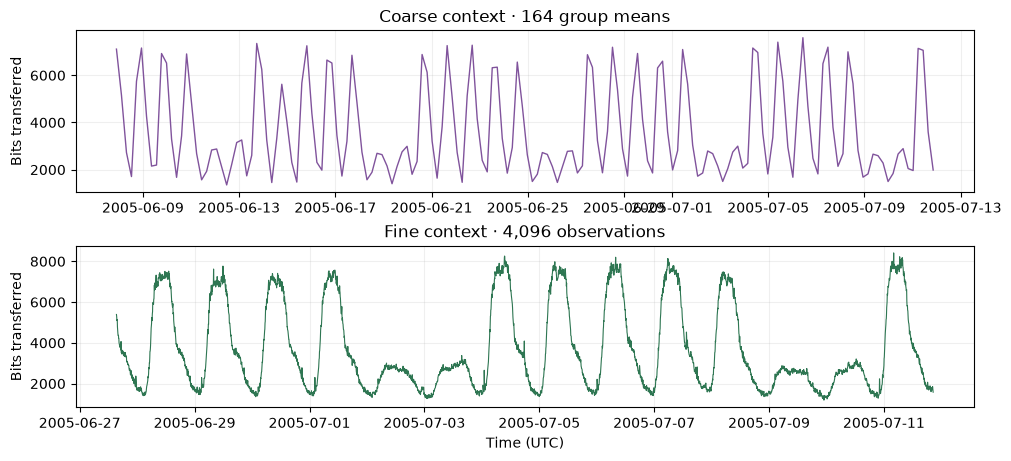

In [3]:
geometry = model.describe()
group_size = geometry["aggregation"]
coarse_count = min(len(history) // group_size, geometry["coarse_context"])
coarse_source = history.tail(coarse_count * group_size)
coarse_means = coarse_source.to_numpy().reshape(coarse_count, group_size).mean(axis=1)
coarse_clock = coarse_source.index[group_size - 1::group_size]
fine = history.tail(geometry["fine_context"])

fig, (coarse_ax, fine_ax) = plt.subplots(2, 1, figsize=(10, 4.5), layout="constrained")
coarse_ax.plot(coarse_clock, coarse_means, color="#80539C", linewidth=1)
coarse_ax.set(title=f"Coarse context · {coarse_count} group means", ylabel=units)
fine_ax.plot(fine.index, fine, color="#2E7652", linewidth=0.8)
fine_ax.set(title=f"Fine context · {len(fine):,} observations", xlabel="Time (UTC)", ylabel=units)
for ax in (coarse_ax, fine_ax):
    ax.grid(alpha=0.2)
display(fig)
plt.close(fig)

## Forecast the holdout

Supply one timestamp per history value. CTSM uses past timestamps to build daily
and weekly features. The forecast returns 15 quantile curves. Use P50 as the point
forecast and P10–P90 for the interval shown here.

Holdout MAE (Bits transferred): 377.866


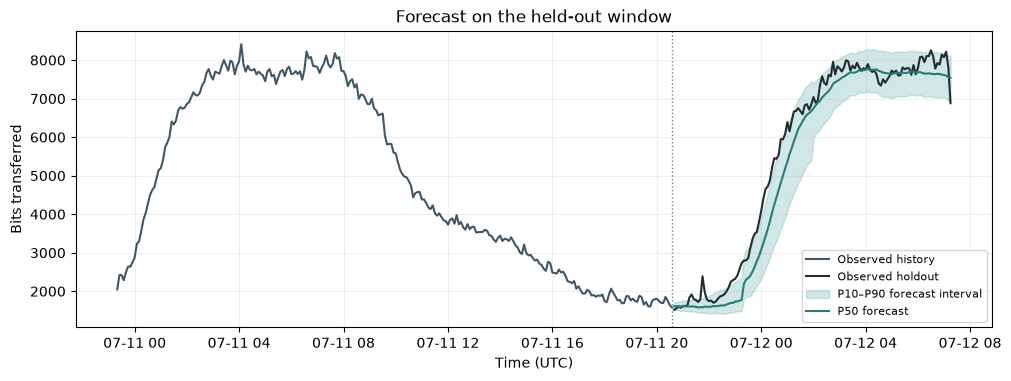

In [4]:
def plot_forecast(history, forecast_clock, quantiles, title, actual=None):
    fig, ax = plt.subplots(figsize=(10, 3.7), layout="constrained")
    recent = history.tail(256)
    ax.plot(recent.index, recent, color="#405766", label="Observed history")
    if actual is not None:
        ax.plot(actual.index, actual, color="#202B33", label="Observed holdout")
    ax.fill_between(
        forecast_clock, quantiles["0.1"], quantiles["0.9"],
        color="#49A19D", alpha=0.25, label="P10–P90 forecast interval",
    )
    ax.plot(forecast_clock, quantiles["0.5"], color="#247D77", label="P50 forecast")
    ax.axvline(history.index[-1], color="#72828B", linestyle=":", linewidth=1)
    ax.set(title=title, xlabel="Time (UTC)", ylabel=units)
    ax.grid(alpha=0.2)
    ax.legend(loc="best", fontsize=8)
    display(fig)
    plt.close(fig)


holdout = model.forecast(
    history.to_numpy(), timestamps=history.index.to_numpy(), horizon_len=HORIZON,
)[0]["quantiles"]
mae = np.abs(actual.to_numpy() - holdout["0.5"]).mean()
print(f"Holdout MAE ({units}): {mae:,.3f}")
plot_forecast(history, actual.index, holdout, "Forecast on the held-out window", actual)

## Forecast beyond the observed series

Use all observations as context. The future index is for plotting. The forecast
call still receives only observed values and their timestamps.

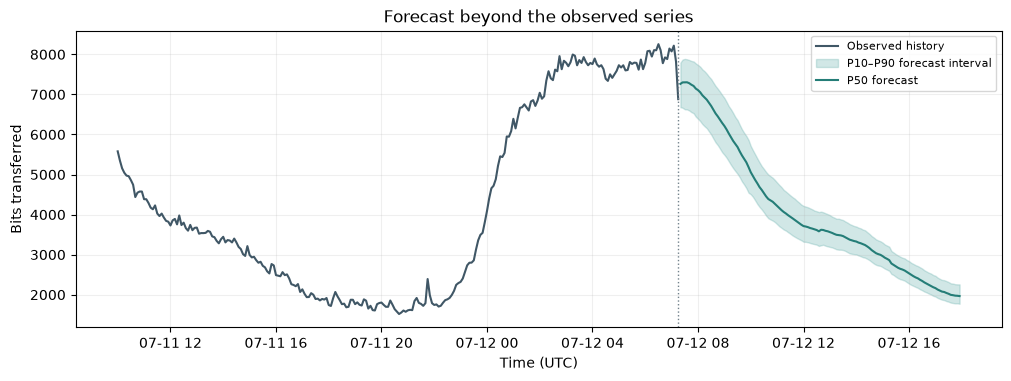

In [5]:
future = model.forecast(
    series.to_numpy(), timestamps=series.index.to_numpy(), horizon_len=HORIZON,
)[0]["quantiles"]
future_clock = pd.date_range(series.index[-1] + cadence, periods=HORIZON, freq=cadence)
plot_forecast(series, future_clock, future, "Forecast beyond the observed series")